In [1]:
import sys
import pandas as pd

import numpy as np
%load_ext autoreload
%autoreload 2

import mvEEG.mvEEG as mvEEG
import tqdm.auto as ta

from sklearn.covariance import LedoitWolf
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.preprocessing import LabelEncoder
from mne.parallel import parallel_func

import matplotlib.pyplot as plt
import seaborn as sns 
from os import path

from glob import glob

import mne_bids

In [2]:
OVERWRITE = True
RUN_DESCRIPTION = "signedDprime"  # description for saving outputs, either "signedDprime" or "signedCorrWhite"
SEED = 2026  # random seed for reproducibility, reset per subject

if RUN_DESCRIPTION == "signedCorrWhite":
    # if correlation whitened, then we need to zscore the data before computing RDMs
    from scipy.stats import zscore

    CORRWHITE = True
elif RUN_DESCRIPTION == "signedDprime":
    CORRWHITE = False

In [3]:
def _mean_by_condition(X, conds):
    """
    computes the average of each condition in X, ordered by conds
    returns a n_conditions x n_channels array
    """
    avs = np.zeros((len(np.unique(conds)), *X.shape[1:]))
    for cond in sorted(np.unique(conds)):
        X_cond = X[conds == cond]
        avs[cond] = X_cond.mean(axis=0)
    return avs


def _means_and_prec(X, conds, CORRWHITE=CORRWHITE):
    """
    Returns condition averages and demeaned inverse covariance
    Covariance is regularized by ledoit-wolf procedure
    """
    cond_means = _mean_by_condition(X, conds)
    cond_means_for_each_trial = cond_means[conds]
    X_demean = X - cond_means_for_each_trial  # demean
    if CORRWHITE:
        # if correlation whitened, then we need to zscore the data before computing RDMs
        # the covariance matrix will then approximate the correlation matrix, and the precision matrix will be the inverse correlation matrix
        X_demean = zscore(X_demean, axis=0)

    return cond_means, LedoitWolf(assume_centered=True).fit(X_demean).precision_


def _calc_rdm_crossnobis_single(meas1, meas2, noise):
    """
    Calculates RDM using crossnobis distance using means from x and y, and covariance
    Largely taken from https://github.com/rsagroup/rsatoolbox/blob/main/src/rsatoolbox/rdm/calc.py#L429
    Updated to return the signed square root of the RDM because
    LDC is an estimator of the squared mahalonobis distance
    """
    kernel = meas1 @ noise @ meas2.T
    rdm = np.expand_dims(np.diag(kernel), 0) + np.expand_dims(np.diag(kernel), 1) - kernel - kernel.T
    return np.sign(rdm) * np.sqrt(np.abs(rdm))  # NOTE: we are converting to signed d' here


def _crossnobis_single(X_train, conds_train, X_test, conds_test):
    """
    Uses condition means from both train and test, but only uses the training
    examples to compute the noise covariance/precision matrix. You may have another
    preference, but I did it this way to avoid train-test leakage.
    """
    means_train, noise_train = _means_and_prec(X_train, conds_train)
    means_test = _mean_by_condition(X_test, conds_test)
    rdm = _calc_rdm_crossnobis_single(means_train, means_test, noise_train)
    return rdm


def _crossnobis_train_test_across_time(Xdata, y, train, test, cond_order):
    # assumes Xdata is n_trials x n_features x n_times

    X_train, y_train = Xdata[train], y[train]
    X_test, y_test = Xdata[test], y[test]

    # calculate RDMS over time for this fold
    rdms = [_crossnobis_single(X_train[..., t], y_train, X_test[..., t], y_test) for t in range(Xdata.shape[-1])]

    # concatenate over time and resort to the given cond_order
    return np.stack(rdms, axis=2)[np.ix_(cond_order, cond_order)]


def crossnobis(Xdata, ydata, cond_order, test_size=0.5, n_splits=1000, n_jobs=-1):
    """
    Wrapper for a parallel function to calculate a series of crossnobis distances
    n_splits and n_jobs should be given as arguments upon class initialization


    """

    enc = LabelEncoder()  # converts condition labels to integer codes
    conds = enc.fit_transform(ydata)
    cond_order = enc.transform(cond_order)  # how to resort the final RDMs

    cv = StratifiedShuffleSplit(n_splits=n_splits, test_size=test_size)

    parallel, p_func, _ = parallel_func(_crossnobis_train_test_across_time, n_jobs)
    rdms = parallel(
        p_func(Xdata=Xdata, y=conds, train=train_idx, test=test_idx, cond_order=cond_order)
        for train_idx, test_idx in cv.split(Xdata, conds)
    )

    rdms = np.stack(rdms, axis=0)
    return rdms.mean(0)  # average over folds

In [4]:
# TODO:
# incorporate the following code to handle the first 2 subs makeup trials
# if subid == 1:  # sub 1 had weird makeup trials, with values in wrong columns
#     to_replace = pd.Series(trial_conds).isnull().values
#     trial_conds[to_replace] = beh["relevant_probe_bin"].values[to_replace]

In [5]:
import json

with open("rejected_subs.json", "r") as f:
    rejected_subs = json.load(f)
rejected_subs

['006', '008', '017', '018', '020', '023', '024', '016']

In [6]:
code_dict = {
    "A2N": 12,
    "A4N": 14,
    "A6N": 16,
    "A8N": 18,
    "A2P": 22,
    "A4P": 24,
    "A6P": 26,
    "A8P": 28,
    "M2N": 32,
    "M4N": 34,
    "M6N": 36,
    "M8N": 38,
    "M2P": 42,
    "M4P": 44,
    "M6P": 46,
    "M8P": 48,
}
# setting the order of the conditions in the RDMs
conditions = [
    "A2N",
    "A4N",
    "A6N",
    "A8N",
    "A2P",
    "A4P",
    "A6P",
    "A8P",
    "M2N",
    "M4N",
    "M6N",
    "M8N",
    "M2P",
    "M4P",
    "M6P",
    "M8P",
]

ROOT = "../data/derivatives"
DATA_DIR = ROOT
EXPERIMENT_NAME = "banyan"
dropped_chans = {"eeg": ["TP9", "Fp1", "Fp2"], "eog": "ALL", "eyegaze": "ALL", "pupil": "ALL", "misc": "ALL"}
# EOG and EYE channels will be analyzed separately, to see if they drive decoding results
# EOG_CHANS = ["HEOG", "VEOG"]
# EYE_CHANS = ["xpos_left", "xpos_right", "ypos_left", "ypos_right"]

SUB_IGNORE_CHANS = {}
bad_epochs = (
    {  # epochs which didn't align with eye tracking for one reason or another, and were excluded during preprocessing
        "010": [0, 1, 2, 3],
        "011": [971],
        "017": [1588],
        "031": [1571],
    }
)
old_beh_format = ["001", "002"]
isub_makeup_error_trials = {"001": 2}  # after exclusion, the last n trials which need dropped due to errors in saving

wrangl = mvEEG.Wrangler(
    data_dir=DATA_DIR,
    experiment_name=EXPERIMENT_NAME,
    dropped_chans=dropped_chans,
    t_win=50,
    t_step=25,
    trim_timepoints=[-350, 1000],
    trial_bin_size=15,
    n_folds=2,  # NOTE: _not_ using wrangler n_folds here
)

delay_window = (wrangl.t > 300) & (
    wrangl.t < 900
)  # time window to average distances over, only includes when probes could appear

In [7]:
def load_behavioral_data(wrangl, isub):
    # get all behavioral files for this subject
    filey = wrangl.bids_path.copy().update(
        subject=wrangl.subs[isub], datatype="beh", suffix="beh", description=None, extension=".tsv"
    )
    beh = pd.read_csv(filey.fpath, sep="\t", index_col=0)
    beh = beh.loc[(beh.REJ != True)].reset_index(
        drop=True
    )  # remove real time eye tracking rejects, which aren't in the EEG
    # NOTE on above - redos have REJ column but Nan values for keeps
    beh = beh.drop(bad_epochs.get(wrangl.subs[isub], [])).reset_index(
        drop=True
    )  # drop bad epochs due to sync errors with eye tracking
    beh = beh.loc[~wrangl.artifacts[isub], :].reset_index(
        drop=True
    )  # drop epochs marked as artifacts during preprocessing
    if wrangl.subs[isub] in old_beh_format:
        beh["block_condition"] = beh["Block Condition"]

    return beh

  0%|          | 0/34 [00:00<?, ?it/s]

Subject 001 condition counts: M8P    90
M6P    90
M8N    90
M4P    90
A4N    90
A6N    90
A8P    90
A2N    90
M2N    89
M2P    89
M6N    89
A2P    89
A4P    89
A8N    89
A6P    89
M4N    88
Name: count, dtype: int64


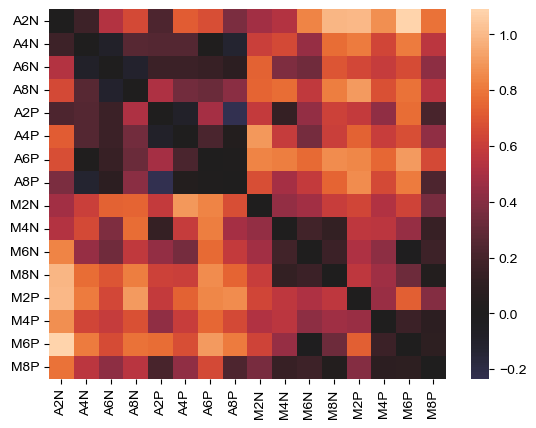

Subject 002 condition counts: A6N    78
A8N    78
A4N    77
A2N    74
A2P    74
A4P    73
A6P    73
A8P    72
M8N    71
M2N    70
M4N    70
M8P    67
M6N    66
M6P    64
M4P    63
M2P    61
Name: count, dtype: int64


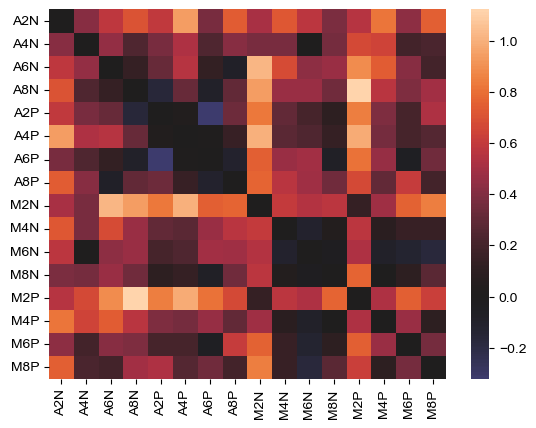

Subject 003 condition counts: A6N    89
A2P    89
A8N    88
A6P    88
M2N    87
M6P    87
A4P    86
A4N    86
M8N    84
A8P    84
M6N    83
M8P    83
A2N    83
M2P    82
M4P    81
M4N    80
Name: count, dtype: int64


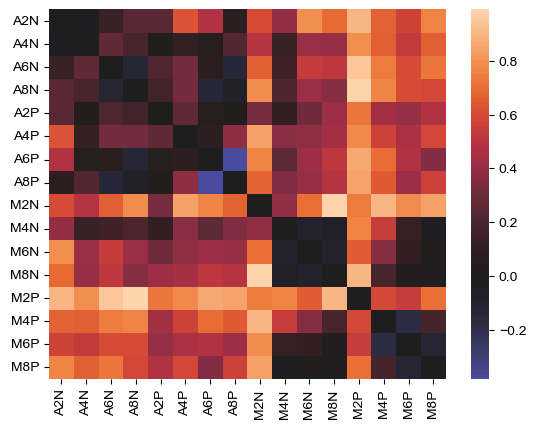

Subject 004 condition counts: A2N    89
A2P    88
A6N    88
A8P    88
A4N    87
A8N    87
M2N    87
A4P    86
M6N    85
M2P    85
A6P    84
M4N    84
M8P    83
M4P    83
M6P    82
M8N    81
Name: count, dtype: int64


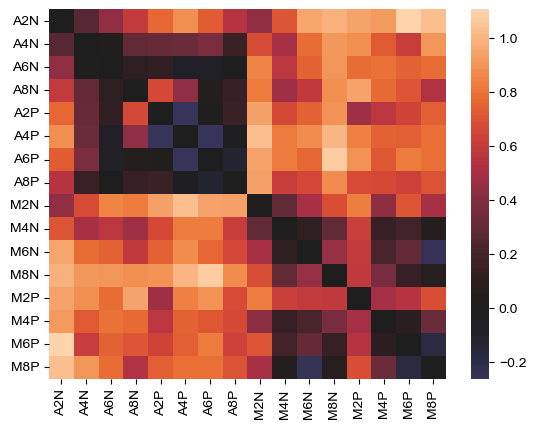

Subject 005 condition counts: A6N    85
A2N    84
A4N    84
A4P    84
A2P    83
A6P    83
M8P    81
A8N    81
A8P    81
M2N    80
M2P    80
M6N    80
M8N    80
M6P    79
M4N    78
M4P    69
Name: count, dtype: int64


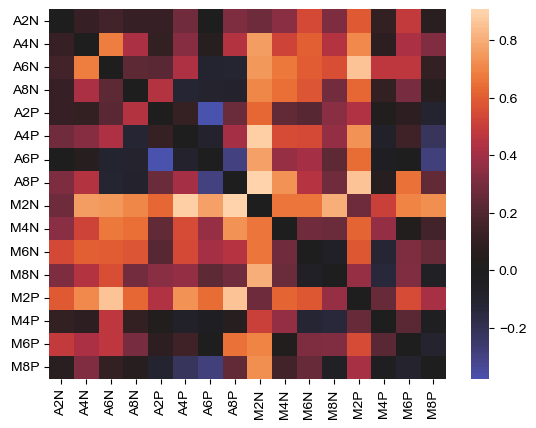

Skipping 006 due to rejection in trial counts or behavioral analyses
Subject 007 condition counts: A2P    89
A6P    89
A2N    89
A8P    86
A8N    86
M2P    85
A6N    84
A4P    84
M2N    83
M6N    82
A4N    82
M4N    81
M8N    79
M4P    77
M8P    75
M6P    72
Name: count, dtype: int64


/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


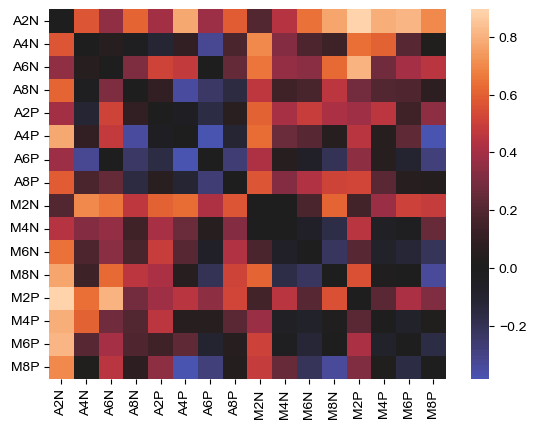

Skipping 008 due to rejection in trial counts or behavioral analyses
Subject 009 condition counts: M4P    83
M6N    83
M2N    80
A8N    80
A4P    80
M4N    79
M8P    79
A8P    79
M2P    78
A6P    78
A2N    78
A4N    78
M6P    76
A2P    75
A6N    74
M8N    73
Name: count, dtype: int64


/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


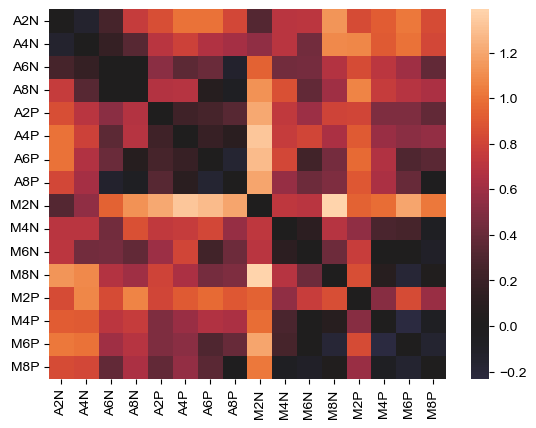

Subject 010 condition counts: A8P    86
A2P    86
A2N    84
A8N    83
A4N    79
A6N    78
A4P    73
M6P    73
A6P    72
M6N    72
M8N    68
M4N    68
M2P    67
M4P    66
M8P    65
M2N    64
Name: count, dtype: int64


/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


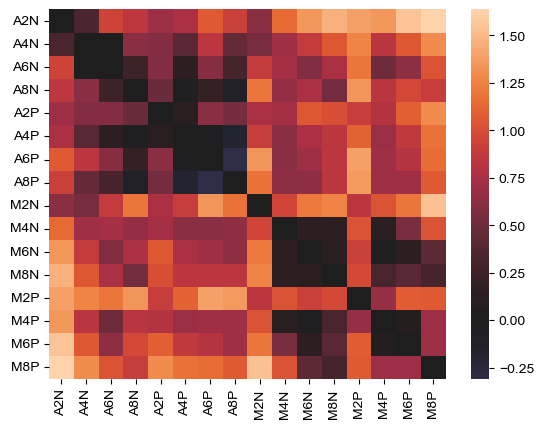

Subject 011 condition counts: M8N    90
M4N    89
A6N    89
A8N    89
A8P    89
A2N    89
M6N    88
A4N    88
M4P    87
M8P    87
M6P    86
M2N    86
A6P    86
A4P    85
A2P    84
M2P    81
Name: count, dtype: int64


/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


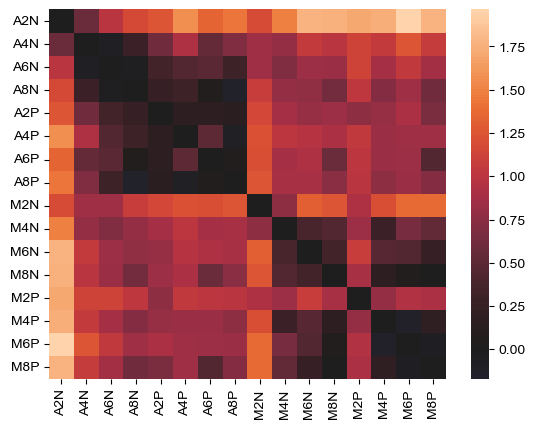

Subject 012 condition counts: A2P    89
A6P    88
A8N    88
A8P    88
M2P    88
A4P    87
A2N    87
A6N    86
A4N    86
M8N    86
M2N    83
M8P    83
M4P    82
M6N    81
M4N    81
M6P    76
Name: count, dtype: int64


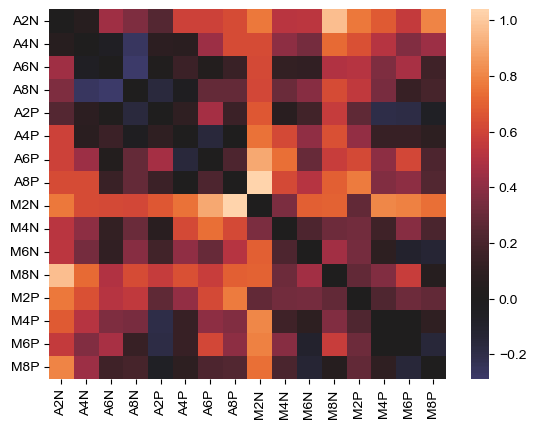

Subject 013 condition counts: M2N    90
M6P    90
A2N    90
M8N    89
M6N    89
A4P    89
A4N    89
A8P    89
M8P    88
M2P    88
A6N    87
A8N    87
A6P    87
M4P    86
M4N    86
A2P    86
Name: count, dtype: int64


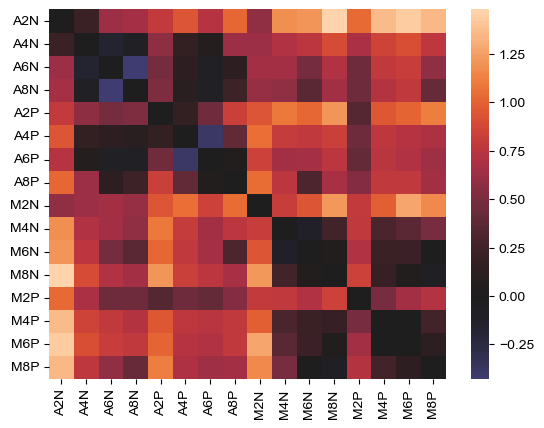

Subject 014 condition counts: A2P    87
M2N    87
A6N    86
M6N    86
A8N    85
M4P    85
A4P    84
A2N    84
M2P    84
A8P    82
M4N    82
M8N    82
A4N    81
A6P    80
M8P    80
M6P    79
Name: count, dtype: int64


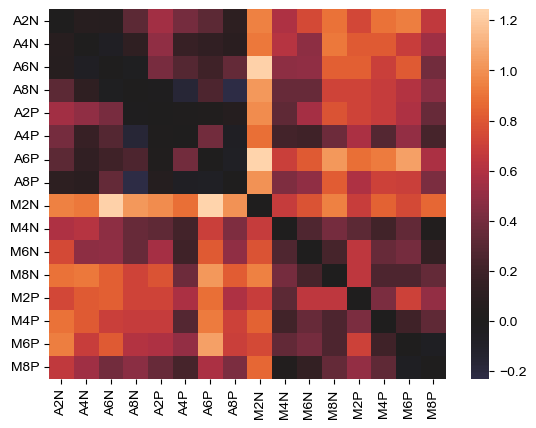

Subject 015 condition counts: M6P    89
M2N    89
M8N    89
M8P    89
A6N    89
A6P    89
A8N    89
M4N    88
M6N    88
A8P    88
A2N    88
A4N    87
M4P    86
A2P    86
M2P    84
A4P    84
Name: count, dtype: int64


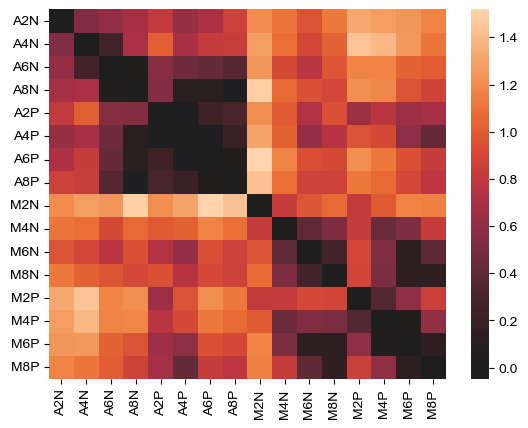

Skipping 016 due to rejection in trial counts or behavioral analyses
Skipping 017 due to rejection in trial counts or behavioral analyses
Skipping 018 due to rejection in trial counts or behavioral analyses
Subject 019 condition counts: M2N    88
A8P    87
M2P    86
A2N    86
A4P    85
A8N    85
A6N    84
M8N    82
M6P    81
M4N    80
A6P    80
A2P    79
M8P    78
M6N    78
A4N    78
M4P    76
Name: count, dtype: int64


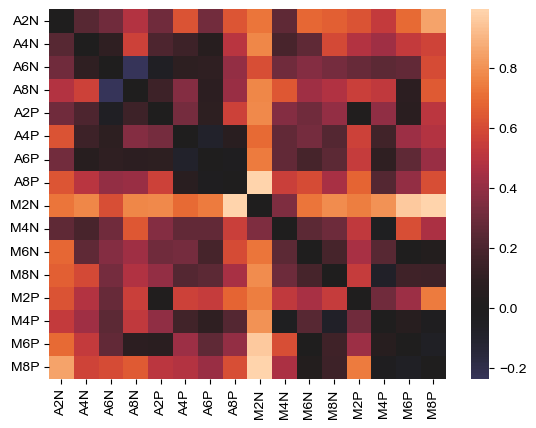

Skipping 020 due to rejection in trial counts or behavioral analyses
Subject 021 condition counts: M4P    83
M2P    83
A2P    82
M8P    81
M6N    80
M8N    80
A8N    80
A8P    79
A2N    79
A4P    79
A6N    78
M2N    77
A6P    77
M6P    76
M4N    74
A4N    72
Name: count, dtype: int64


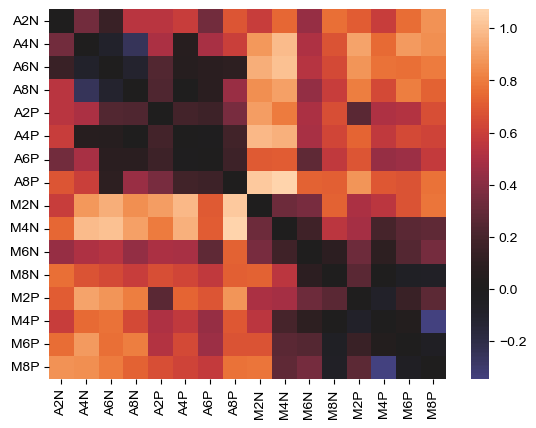

Subject 022 condition counts: A4N    87
A8N    87
A6P    86
M8P    86
A8P    85
M6N    85
M6P    85
M4P    85
M2N    85
A6N    84
M8N    84
M4N    84
A2N    83
A4P    83
A2P    77
M2P    76
Name: count, dtype: int64


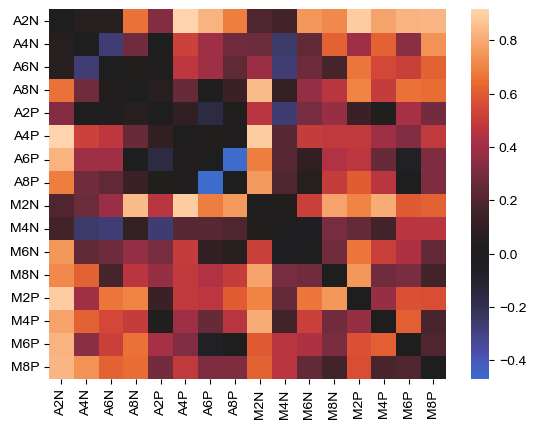

Skipping 023 due to rejection in trial counts or behavioral analyses
Skipping 024 due to rejection in trial counts or behavioral analyses
Subject 025 condition counts: A8N    85
A4N    82
A2N    81
A6N    81
A2P    78
A4P    76
M4P    75
A8P    75
A6P    75
M4N    74
M6P    73
M2N    70
M6N    69
M8P    68
M2P    64
M8N    63
Name: count, dtype: int64


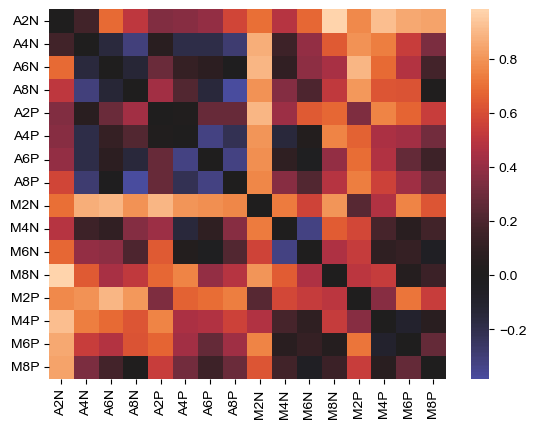

Subject 026 condition counts: A2P    87
A8P    87
M4P    87
M8P    87
M8N    87
A8N    86
A6N    86
A6P    86
A4N    86
A4P    85
M6N    85
M2N    85
A2N    83
M2P    83
M6P    83
M4N    79
Name: count, dtype: int64


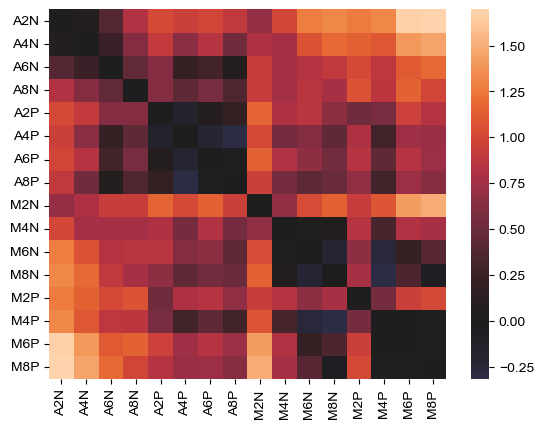

Subject 027 condition counts: M8N    91
A4P    91
M4P    90
M6P    90
M4N    90
A6N    90
A2N    90
A8P    90
A4N    90
A2P    90
M2P    89
M6N    89
M8P    89
M2N    89
A6P    89
A8N    89
Name: count, dtype: int64


/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


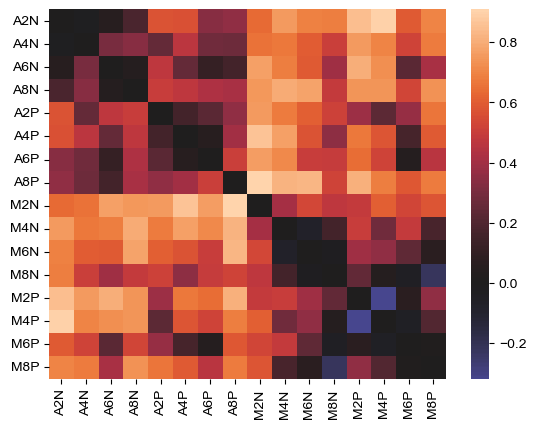

Subject 028 condition counts: A2N    90
A8P    90
M4N    90
M8N    89
M6N    89
A8N    88
A2P    88
A6N    88
A4P    87
M4P    87
M2N    87
A6P    86
A4N    86
M8P    86
M6P    86
M2P    85
Name: count, dtype: int64


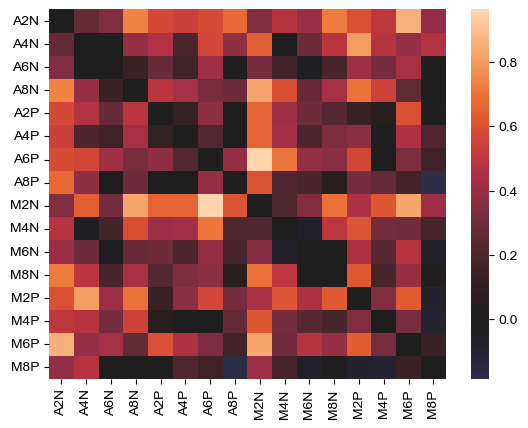

Subject 029 condition counts: A4N    88
A8P    87
A4P    87
M2P    83
A2N    83
A8N    83
A2P    83
A6P    82
M6N    81
M4N    81
M8P    81
M4P    80
M2N    80
M8N    79
A6N    79
M6P    78
Name: count, dtype: int64


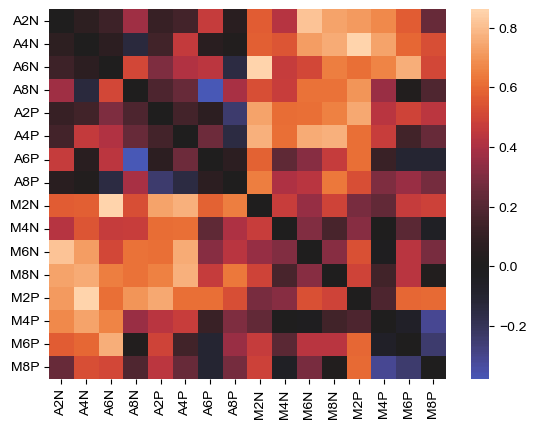

Subject 030 condition counts: A6P    88
A8N    88
A4P    86
A2N    86
A4N    85
M2N    85
M8P    85
A8P    84
M4P    81
M6N    81
A2P    80
M4N    80
A6N    79
M2P    79
M6P    76
M8N    76
Name: count, dtype: int64


/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


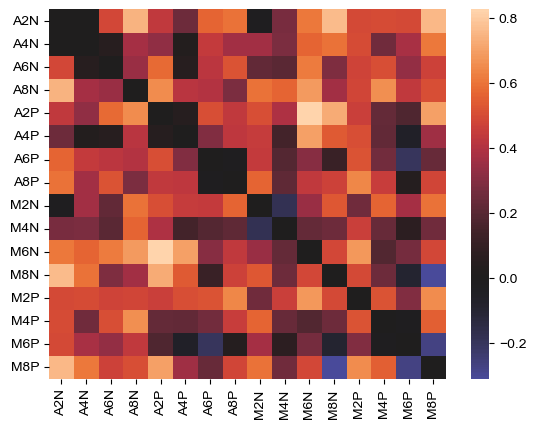

Subject 031 condition counts: A6P    89
A4N    89
A6N    89
A8P    88
A2P    87
A8N    87
A2N    86
A4P    85
M8N    84
M2N    84
M8P    84
M6P    83
M4P    82
M6N    81
M2P    81
M4N    79
Name: count, dtype: int64


/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


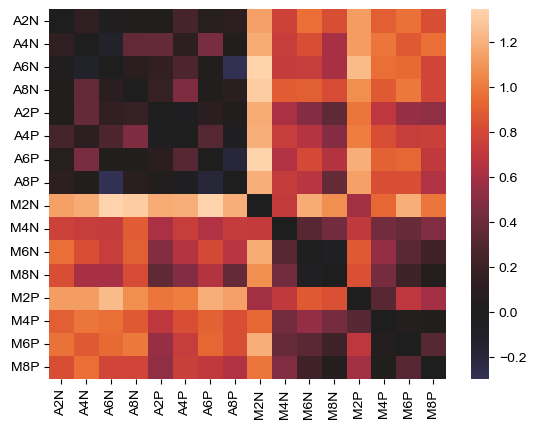

Subject 032 condition counts: A2N    91
A6N    90
A6P    89
A8N    88
A4P    88
M8P    88
M6P    88
M4P    88
A4N    87
A8P    87
A2P    86
M2P    86
M6N    85
M8N    85
M2N    85
M4N    83
Name: count, dtype: int64


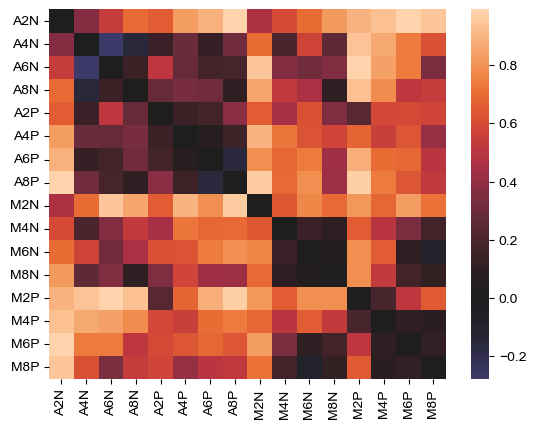

Subject 033 condition counts: M4N    90
A8P    90
M4P    89
M8N    89
M2N    88
M8P    88
M6P    87
M2P    87
A8N    87
A2P    86
A2N    86
A6P    86
A6N    86
A4N    86
M6N    85
A4P    80
Name: count, dtype: int64


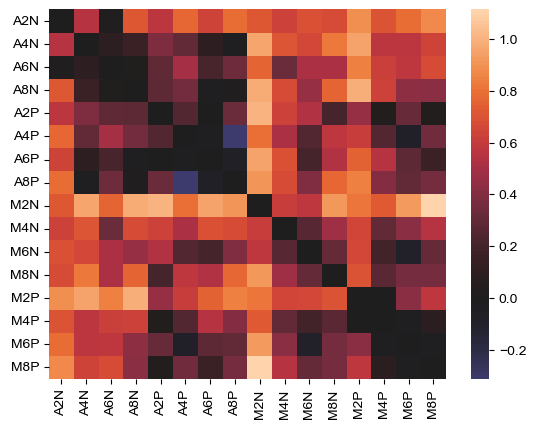

Subject 034 condition counts: A8N    92
A4P    91
A6P    90
A2P    90
M2N    90
A6N    89
A2N    88
A8P    88
A4N    88
M2P    85
M4P    84
M4N    83
M8P    83
M8N    82
M6N    81
M6P    78
Name: count, dtype: int64


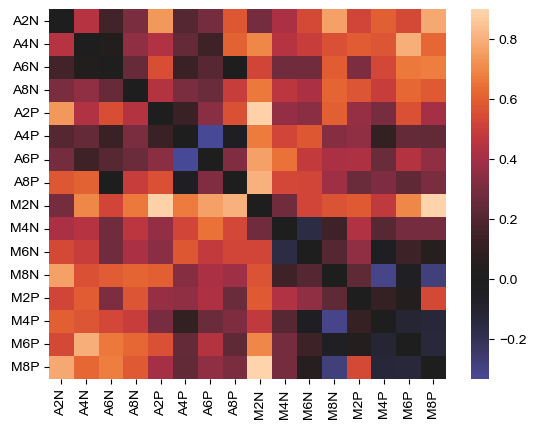

In [8]:
for isub in ta.tqdm(range(wrangl.nsub)):
    if wrangl.subs[isub] in rejected_subs:
        print(f"Skipping {wrangl.subs[isub]} due to rejection in trial counts or behavioral analyses")
        continue

    sub_path = mne_bids.BIDSPath(
        root=ROOT,
        task=EXPERIMENT_NAME,
        subject=wrangl.subs[isub],
        datatype="RDMs",
        description=RUN_DESCRIPTION,
        extension=".npy",
        suffix="rdm",
        check=False,
    )
    sub_path.mkdir()
    if sub_path.fpath.exists() and not OVERWRITE:
        print(f"Skipping {wrangl.subs[isub]}; already exists and not overwriting")
        continue

    # Load the data
    Xdata, ydata = wrangl.load_eeg(isub, reject=True, drop_chans_manual=SUB_IGNORE_CHANS.get(wrangl.subs[isub], []))
    beh = load_behavioral_data(wrangl, isub)
    assert Xdata.shape[0] == beh.shape[0], "Mismatch between EEG epochs and behavioral data"
    if wrangl.subs[isub] in isub_makeup_error_trials:
        beh = beh.iloc[: -isub_makeup_error_trials[wrangl.subs[isub]], :].reset_index(
            drop=True
        )  # drop last n trials to make up for lost trials during recording error
        Xdata = Xdata[: -isub_makeup_error_trials[wrangl.subs[isub]], :, :]
        ydata = ydata[: -isub_makeup_error_trials[wrangl.subs[isub]]]
    # drop some broken makeup trials in the first 2 subs
    # beh_keep_idx = beh.loc[:, "n_targets"].isin(["2", "4", "6", "8", 2, 4, 6, 8])
    # beh = beh.loc[beh_keep_idx, :].reset_index(drop=True)
    # Xdata = Xdata[beh_keep_idx, :, :]
    # ydata = ydata[beh_keep_idx]

    # keep only main task conditions, not trials with probes
    keep_cond_idx = (beh.target_present == 0).values
    Xdata = Xdata[keep_cond_idx]
    ydata = ydata[keep_cond_idx]
    beh = beh.loc[keep_cond_idx, :].reset_index(drop=True)

    trial_conds = beh["trial_condition"].values
    if wrangl.subs[isub] in ["001", "002"]:  # first 2 subs had weird makeup trials, with values in wrong columns
        to_replace = pd.Series(trial_conds).isnull().values
        trial_conds[to_replace] = beh["relevant_probe_bin"].values[to_replace]
    print(f"Subject {wrangl.subs[isub]} condition counts:", pd.Series(trial_conds).value_counts())

    np.random.seed(SEED)  # for reproducibility
    sub_rdms = crossnobis(Xdata, trial_conds, conditions, n_splits=2_500, n_jobs=-1)
    np.save(sub_path.copy(), sub_rdms)

    # plot delay-period RDM
    sub_rdm_delay = sub_rdms[..., delay_window].mean(-1)
    sns.heatmap(sub_rdm_delay, xticklabels=conditions, yticklabels=conditions, center=0)
    plt.show()
    plt.close()